# Caption analysis

Textual exploration of the COCO captions: length, vocabulary, part-of-speech, attributes, context and Zipf's law, followed by caption cleaning and integrity checks.

## Part 1: full COCO train2017 (exploration)

In [1]:
import json
import pandas as pd

with open("../data/captions_train2017.json") as f:
    data = json.load(f)

df = pd.DataFrame(data["annotations"])[["image_id", "id", "caption"]]
print(len(df))
df.head(20)

591753


,image_id,id,caption
0,203564,37,A bicycle replica with a clock as the front wh...
1,322141,49,A room with blue walls and a white sink and door.
2,16977,89,A car that seems to be parked illegally behind...
3,106140,98,A large passenger airplane flying through the ...
4,106140,101,There is a GOL plane taking off in a partly cl...
5,322141,109,Blue and white color scheme in a small bathroom.
6,322141,121,This is a blue and white bathroom with a wall ...
7,322141,163,A blue boat themed bathroom with a life preser...
8,203564,181,The bike has a clock as a tire.
9,16977,185,two cars parked on the sidewalk on the street


**Finding.** The full COCO train2017 caption file is loaded into one table with one row per caption.

count    591753.000000
mean         10.457179
std           2.392612
min           5.000000
25%           9.000000
50%          10.000000
75%          11.000000
max          49.000000
Name: n_words, dtype: float64


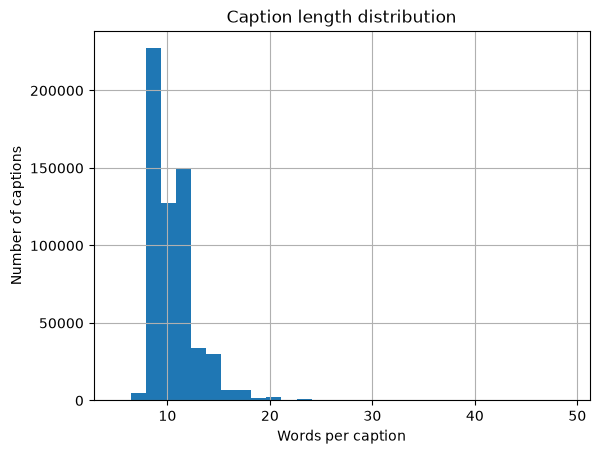

In [2]:
import matplotlib.pyplot as plt

df["n_words"] = df.caption.str.split().str.len()
print(df.n_words.describe())

ax = df.n_words.hist(bins=30)
ax.set_xlabel("Words per caption")
ax.set_ylabel("Number of captions")
ax.set_title("Caption length distribution")
plt.savefig("../figures/caption_analysis/caption_length.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding.** Captions are short: about 10.5 words on average, with a narrow spread, so the generated captions should also be short.

In [3]:
from collections import Counter

df["caption_clean"] = (df.caption.str.lower()
                       .str.replace(r"[^\w\s]", " ", regex=True)
                       .str.replace(r"\s+", " ", regex=True)
                       .str.strip())

words = [w for c in df.caption_clean for w in c.split()]
vocab = Counter(words)

print("Total words:", len(words))
print("Vocabulary size (unique words):", len(vocab))
print("Words that appear only once:", sum(1 for n in vocab.values() if n == 1))

Total words: 6200961
Vocabulary size (unique words): 26850
Words that appear only once: 10621


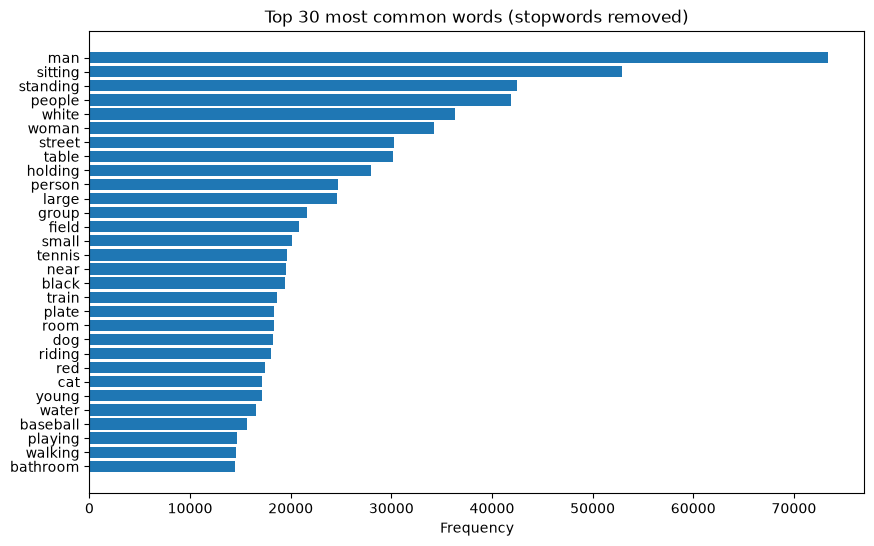

In [4]:
from spacy.lang.en.stop_words import STOP_WORDS

top = [(w, n) for w, n in vocab.most_common() if w not in STOP_WORDS][:30]
labels, counts = zip(*top)

plt.figure(figsize=(10, 6))
plt.barh(labels[::-1], counts[::-1])
plt.xlabel("Frequency")
plt.title("Top 30 most common words (stopwords removed)")
plt.savefig("../figures/caption_analysis/top_words.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
top3 = [w for w, n in vocab.most_common() if w not in STOP_WORDS][:3]
once = sum(1 for n in vocab.values() if n == 1)

print("Findings so far")
print(f"- Captions average {df.n_words.mean():.1f} words (min {df.n_words.min()}, max {df.n_words.max()}).")
print(f"- The vocabulary has {len(vocab):,} unique words, and {once:,} of them appear only once.")
print(f"- The most common content words are {top3[0]}, {top3[1]} and {top3[2]}.")

Findings so far
- Captions average 10.5 words (min 5, max 49).
- The vocabulary has 26,850 unique words, and 10,621 of them appear only once.
- The most common content words are man, sitting and standing.


**Finding.** The vocabulary is small and very uneven: a few words are extremely frequent, while about 40% of the 26,850 unique words appear only once. The most common content words are man, sitting and standing, so captions mostly describe people and their posture.

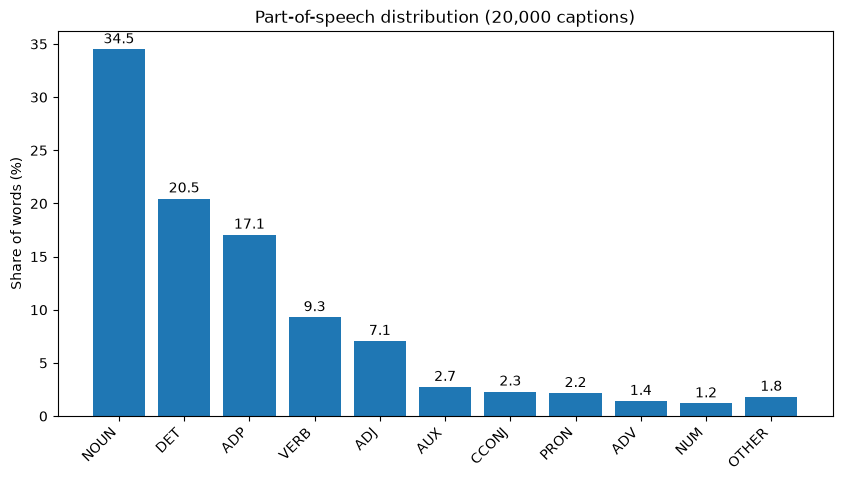

NOUN: 34.5%
DET: 20.5%
ADP: 17.1%
VERB: 9.3%
ADJ: 7.1%
AUX: 2.7%


In [6]:
import spacy
from collections import Counter

nlp = spacy.load("en_core_web_sm", disable=["ner", "parser", "lemmatizer"])

sample = df.caption.sample(20000, random_state=42)
pos_counts = Counter(t.pos_ for d in nlp.pipe(sample, batch_size=500) for t in d if t.pos_ != "PUNCT")

total = sum(pos_counts.values())
pos_share = {k: v / total * 100 for k, v in pos_counts.most_common()}

top = dict(list(pos_share.items())[:10])
top["OTHER"] = sum(list(pos_share.values())[10:])

plt.figure(figsize=(10, 5))
bars = plt.bar(top.keys(), top.values())
plt.bar_label(bars, fmt="%.1f", padding=2)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Share of words (%)")
plt.title("Part-of-speech distribution (20,000 captions)")
plt.savefig("../figures/caption_analysis/pos_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

for k, v in list(pos_share.items())[:6]:
    print(f"{k}: {v:.1f}%")

**Finding.** Nouns are the largest category, then verbs and adjectives. Captions are noun-centred descriptions of objects and scenes.

Share of captions mentioning each category:
  colours: 16.6%
  sizes: 10.1%
  shapes: 0.3%
  numbers: 11.4%


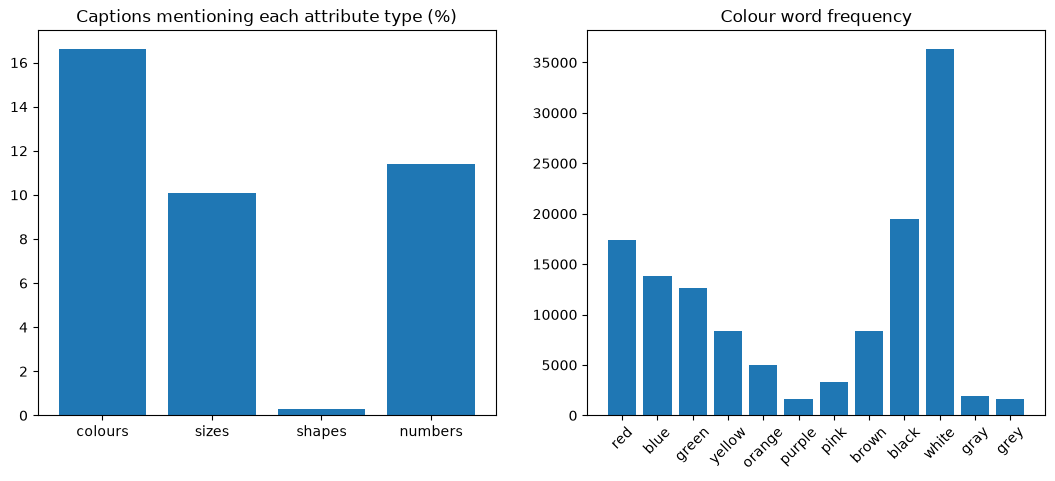

In [7]:
lexicons = {
    "colours": ["red","blue","green","yellow","orange","purple","pink","brown","black","white","gray","grey"],
    "sizes": ["big","large","small","little","tiny","huge","tall"],
    "shapes": ["round","square","rectangular","circular","oval"],
    "numbers": ["one","two","three","four","five","six"],
}

word_sets = df.caption_clean.str.split().apply(set)

print("Share of captions mentioning each category:")
cat_share = {}
for name, words in lexicons.items():
    cat_share[name] = word_sets.apply(lambda s: bool(s & set(words))).mean() * 100
    print(f"  {name}: {cat_share[name]:.1f}%")

colour_counts = {c: vocab[c] for c in lexicons["colours"]}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(cat_share.keys(), cat_share.values())
axes[0].set_title("Captions mentioning each attribute type (%)")
axes[1].bar(colour_counts.keys(), colour_counts.values())
axes[1].set_title("Colour word frequency")
axes[1].tick_params(axis="x", rotation=45)
plt.savefig("../figures/caption_analysis/attributes.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding.** Colour words are common, while shape words are very rare. Captions describe what things are and what they do more than how they are shaped.

indoor: 7.8%
outdoor: 19.2%
day: 0.8%
night: 0.8%


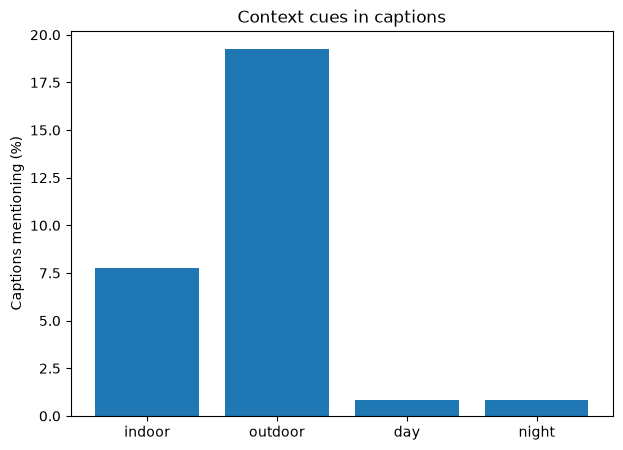

In [8]:
contexts = {
    "indoor": ["kitchen","bathroom","bedroom","indoor","inside","office","restaurant","living"],
    "outdoor": ["street","beach","field","park","outside","road","grass","snow","sky","city"],
    "day": ["day","sunny","morning","daytime","sunlight"],
    "night": ["night","dark","evening","sunset"],
}

ctx_share = {}
for name, words in contexts.items():
    ctx_share[name] = word_sets.apply(lambda s: bool(s & set(words))).mean() * 100
    print(f"{name}: {ctx_share[name]:.1f}%")

plt.figure(figsize=(7, 5))
plt.bar(ctx_share.keys(), ctx_share.values())
plt.ylabel("Captions mentioning (%)")
plt.title("Context cues in captions")
plt.savefig("../figures/caption_analysis/context.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding.** Indoor and outdoor words are far more frequent than day or night words, so the lighting or time of day is rarely described.

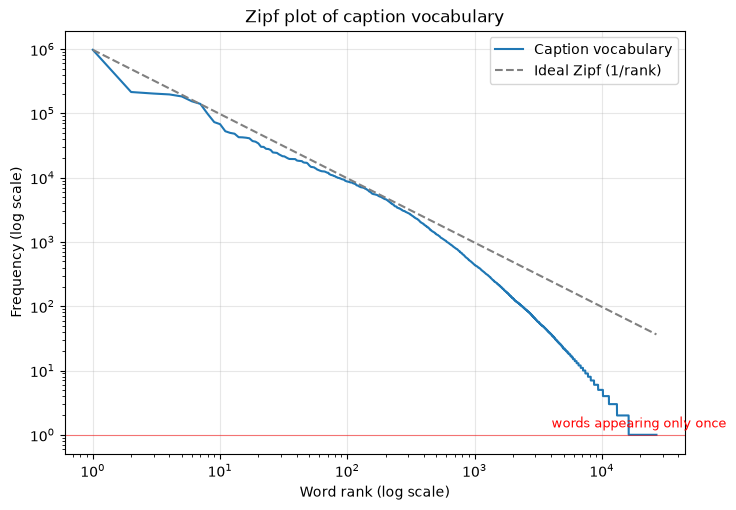

In [9]:
import numpy as np

freqs = np.array(sorted(vocab.values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)

plt.figure(figsize=(8, 5.5))
plt.loglog(ranks, freqs, label="Caption vocabulary")
plt.loglog(ranks, freqs[0] / ranks, "--", color="gray", label="Ideal Zipf (1/rank)")
plt.axhline(1, color="red", linewidth=0.8, alpha=0.5)
plt.text(len(freqs) * 0.15, 1.3, "words appearing only once", color="red", fontsize=9)
plt.grid(True, which="major", alpha=0.3)
plt.xlabel("Word rank (log scale)")
plt.ylabel("Frequency (log scale)")
plt.title("Zipf plot of caption vocabulary")
plt.legend()
plt.savefig("../figures/caption_analysis/zipf.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding.** The word frequencies follow Zipf's law: a straight line on the log-log plot, with a long tail of rare words.

### Cleaning and integrity checks

The original text is kept in `caption_raw`. The lowercase, punctuation-free text used for analysis is in `caption_clean`.

In [10]:
df["caption_raw"] = df.caption

per_image = df.groupby("image_id").size()
print("Captions per image:\n", per_image.value_counts().sort_index())
print()
print("Empty cleaned captions:", (df.caption_clean.str.len() == 0).sum())
print("Duplicate caption IDs:", df.id.duplicated().sum())
print("Exact duplicate captions within an image:",
      df.duplicated(subset=["image_id", "caption_clean"]).sum())
print("Missing values:\n", df[["caption_raw", "caption_clean"]].isna().sum())

df[["image_id", "id", "caption_raw", "caption_clean"]].to_csv(
    "../data/captions_clean.csv", index=False)
print("\nSaved ../data/captions_clean.csv")

Captions per image:
 5    117972
6       312
7         3
Name: count, dtype: int64

Empty cleaned captions: 0
Duplicate caption IDs: 0
Exact duplicate captions within an image: 310
Missing values:
 caption_raw      0
caption_clean    0
dtype: int64

Saved ../data/captions_clean.csv


### Exploratory 5-caption check on full COCO

This check is only exploratory and runs on the full COCO file. It removes duplicate captions within an image and keeps images with exactly 5 captions. The frozen knowledge base is not rebuilt this way: it keeps the original captions (9,964 images with 5 captions and 36 images with 6).

In [11]:
df_5 = (df.drop_duplicates(subset=["image_id", "caption_clean"])
          .groupby("image_id")
          .head(5))

counts = df_5.groupby("image_id").size()
print(counts.value_counts().sort_index())
print("Images with fewer than 5 captions:", (counts < 5).sum())

3         3
4       281
5    118003
Name: count, dtype: int64
Images with fewer than 5 captions: 284


In [12]:
valid_ids = counts[counts == 5].index
df_5 = df_5[df_5.image_id.isin(valid_ids)]
print("Eligible images:", df_5.image_id.nunique())
print("Eligible captions:", len(df_5))

Eligible images: 118003
Eligible captions: 590015


## Part 2: frozen knowledge base (10,000 images)

The same analysis re-run on the knowledge base selected by the data-cleaning step.

In [13]:
import json
import pandas as pd

with open("../cleaned_dataset/knowledge_base/captions.json") as f:
    kb = json.load(f)

df_kb = pd.DataFrame(kb["annotations"])[["image_id", "id", "caption"]]
df_kb["caption_raw"] = df_kb.caption
df_kb["caption_clean"] = (df_kb.caption.str.lower()
                          .str.replace(r"[^\w\s]", " ", regex=True)
                          .str.replace(r"\s+", " ", regex=True)
                          .str.strip())
print(df_kb.image_id.nunique(), len(df_kb))
print(df_kb.groupby("image_id").size().value_counts().sort_index())

10000 50036
5    9964
6      36
Name: count, dtype: int64


### Anti-leakage audit

The test images must not appear in the knowledge base, and the 100 validation images must come from inside it.

In [14]:
with open("../cleaned_dataset/test/captions.json") as f:
    test = json.load(f)
with open("../cleaned_dataset/validation/captions.json") as f:
    val = json.load(f)

kb_ids = set(df_kb.image_id)
test_ids = set(a["image_id"] for a in test["annotations"])
val_ids = set(a["image_id"] for a in val["annotations"])

print("Test images:", len(test_ids))
print("Test and knowledge base overlap:", len(test_ids & kb_ids))
print("Validation images:", len(val_ids))
print("Validation inside knowledge base:", len(val_ids & kb_ids))
print("Test and validation overlap:", len(test_ids & val_ids))

Test images: 100
Test and knowledge base overlap: 0
Validation images: 100
Validation inside knowledge base: 100
Test and validation overlap: 0


**Finding.** Test and knowledge base share no images (overlap 0), the 100 validation images are all inside the knowledge base, and test and validation do not overlap.

count    50036.000000
mean        10.487629
std          2.419341
min          6.000000
25%          9.000000
50%         10.000000
75%         11.000000
max         47.000000
Name: n_words, dtype: float64
Vocabulary: 9615 Appearing once: 3783


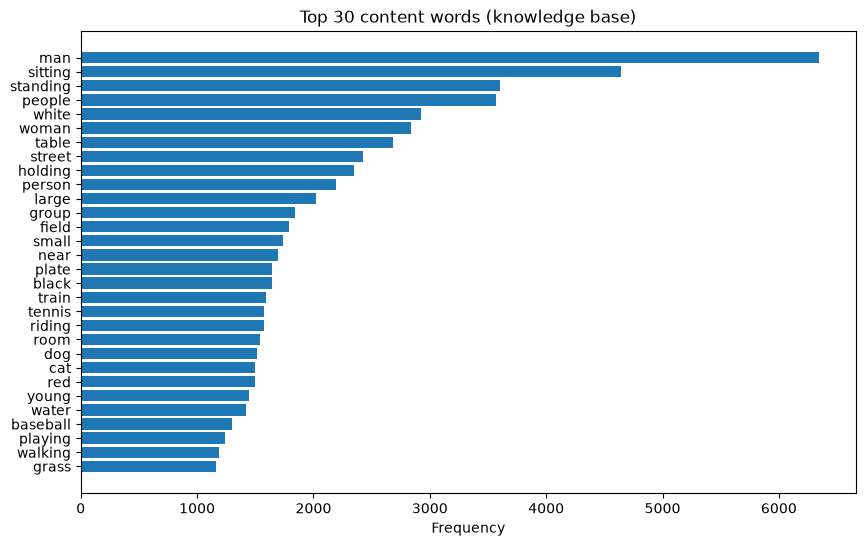

In [15]:
from collections import Counter
import matplotlib.pyplot as plt
from spacy.lang.en.stop_words import STOP_WORDS

df_kb["n_words"] = df_kb.caption_clean.str.split().str.len()
print(df_kb.n_words.describe())

vocab_kb = Counter(w for c in df_kb.caption_clean for w in c.split())
once = sum(1 for n in vocab_kb.values() if n == 1)
print("Vocabulary:", len(vocab_kb), "Appearing once:", once)

top = [(w, n) for w, n in vocab_kb.most_common() if w not in STOP_WORDS][:30]
labels, counts = zip(*top)
plt.figure(figsize=(10, 6))
plt.barh(labels[::-1], counts[::-1])
plt.xlabel("Frequency")
plt.title("Top 30 content words (knowledge base)")
plt.savefig("../figures/caption_analysis/kb_top_words.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding.** Knowledge base captions average 10.5 words (median 10, range 6 to 47). The vocabulary has 9,615 unique words and about 39% appear only once, close to the full COCO pattern, so the sample is representative.

In [16]:
lexicons = {
    "colours": ["red","blue","green","yellow","orange","purple","pink","brown","black","white","gray","grey"],
    "sizes": ["big","large","small","little","tiny","huge","tall"],
    "shapes": ["round","square","rectangular","circular","oval"],
    "numbers": ["one","two","three","four","five","six"],
}

contexts = {
    "indoor": ["kitchen","bathroom","bedroom","indoor","inside","office","restaurant","living"],
    "outdoor": ["street","beach","field","park","outside","road","grass","snow","sky","city"],
    "day": ["day","sunny","morning","daytime","sunlight"],
    "night": ["night","dark","evening","sunset"],
}

In [17]:
import spacy

nlp = spacy.load("en_core_web_sm", disable=["ner", "parser", "lemmatizer"])
pos_counts = Counter(t.pos_ for d in nlp.pipe(df_kb.caption_raw, batch_size=500) for t in d if t.pos_ != "PUNCT")
total = sum(pos_counts.values())
pos_share = {k: v / total * 100 for k, v in pos_counts.most_common()}
for k, v in list(pos_share.items())[:6]:
    print(f"{k}: {v:.1f}%")

ws = df_kb.caption_clean.str.split().apply(set)
groups = {**lexicons, **contexts}
for name, words in groups.items():
    print(f"{name}: {ws.apply(lambda s: bool(s & set(words))).mean() * 100:.1f}%")

NOUN: 34.5%
DET: 20.5%
ADP: 17.0%
VERB: 9.3%
ADJ: 7.1%
AUX: 2.7%
colours: 16.4%
sizes: 10.0%
shapes: 0.3%
numbers: 11.7%
indoor: 7.6%
outdoor: 19.2%
day: 0.8%
night: 0.7%


**Finding.** Nouns make up 34.5% of words, verbs 9.3% and adjectives 7.1%. Colour words appear in 16.4% of captions, shape words in 0.3%, and day or night words in under 1%. These match the full-COCO results.

## Summary

- Knowledge base: 10,000 images and 50,036 captions (9,964 images with 5 captions, 36 with 6).
- Captions average 10.5 words (median 10, range 6 to 47).
- Vocabulary of 9,615 words, 39% of them appearing only once.
- Nouns 34.5%, verbs 9.3%, adjectives 7.1%.
- Colour words in 16.4% of captions, shape words in 0.3%, day or night words in under 1%.
- Most common content words: man, sitting, standing.
- No leakage: test and knowledge base overlap is 0, and the 100 validation images are inside the knowledge base.

In [18]:
import os

os.makedirs("../outputs", exist_ok=True)
df_kb[["image_id", "id", "caption_raw", "caption_clean"]].to_csv("../outputs/kb_captions_clean.csv", index=False)
print("Saved ../outputs/kb_captions_clean.csv")

Saved ../outputs/kb_captions_clean.csv
